# **ViT model (second run)**

 **Mount Drive & Install Packages**

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Install required packages
!pip install transformers timm torchmetrics split-folders
!pip install --upgrade accelerate

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 962.6/962.6 kB 50.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 126.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 96.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 65.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 110.1 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlin

 **Imports**

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from transformers import ViTFeatureExtractor, ViTForImageClassification
from torchmetrics import Accuracy, Precision, Recall, F1Score, AUROC
import splitfolders

# Set random seed
torch.manual_seed(42)
np.random.seed(42)

# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


**Dataset Splitting**

In [ ]:
# Define paths
unsplit_path = "/content/drive/MyDrive/artstyleproject/processeddataset_classification2"
output_path = "/content/processeddataset_classification22"

# Verify and split dataset
if not os.path.exists(unsplit_path):
    print(f"Error: Path not found - {unsplit_path}")
    print("Available folders in /content/drive/MyDrive:")
    !ls "/content/drive/MyDrive"
else:
    print("Dataset found successfully!")
    splitfolders.ratio(
        input=unsplit_path,
        output=output_path,
        seed=42,
        ratio=(0.6, 0.2, 0.2),
        group_prefix=None,
        move=False
    )

Dataset found successfully!


Copying files: 52094 files [42:16, 20.54 files/s]


**Data Loading & Transforms**

In [ ]:
# Define paths
train_dir = os.path.join(output_path, 'train')
val_dir = os.path.join(output_path, 'val')
test_dir = os.path.join(output_path, 'test')

# ViT transforms (second run)
vit_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Create datasets
train_dataset = ImageFolder(root=train_dir, transform=vit_transform)
val_dataset = ImageFolder(root=val_dir, transform=vit_transform)
test_dataset = ImageFolder(root=test_dir, transform=vit_transform)

# Split validation set
val_size = len(val_dataset)
val_indices = list(range(val_size))
val_split = int(val_size * 0.7)  # 70% val, 30% plotting

val_subset = Subset(val_dataset, val_indices[:val_split])
plotting_test_subset = Subset(val_dataset, val_indices[val_split:])

# Data loaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=4)
plotting_test_loader = DataLoader(plotting_test_subset, batch_size=batch_size, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

# Class names
class_names = train_dataset.classes
print("Class names:", class_names)

Class names: ['baroque', 'expressionism', 'impressionism', 'realism', 'romanticism']


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


**Model Initialization**

In [ ]:
# Initialize ViT (second run, google/vit-base-patch16-224)
feature_extractor = ViTFeatureExtractor.from_pretrained("google/vit-base-patch16-224")
model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=len(class_names),
    ignore_mismatched_sizes=True
).to(device)

print(model)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

/usr/local/lib/python3.11/dist-packages/transformers/models/vit/feature_extraction_vit.py:30: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([5]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 768]) in the checkpoint and torch.Size([5, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_features=768, out_features=3072, bias=True)
            (intermed

**Training Setup**

In [ ]:
# Optimizer and loss
optimizer = optim.AdamW(model.parameters(), lr=2e-5)
criterion = nn.CrossEntropyLoss()

# Metrics
accuracy = Accuracy(task="multiclass", num_classes=len(class_names)).to(device)
precision = Precision(task="multiclass", average='macro', num_classes=len(class_names)).to(device)
recall = Recall(task="multiclass", average='macro', num_classes=len(class_names)).to(device)
f1 = F1Score(task="multiclass", average='macro', num_classes=len(class_names)).to(device)
auroc = AUROC(task="multiclass", num_classes=len(class_names)).to(device)

**Training Functiont**

In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10):
    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    best_val_loss = float('inf')
    best_model_weights = None

    start_time = time.time()

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs).logits
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = running_corrects.double() / len(train_loader.dataset)

        train_losses.append(epoch_loss)
        train_accs.append(epoch_acc.cpu())

        val_loss, val_acc = evaluate_model(model, val_loader, criterion)
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_weights = model.state_dict().copy()

        print(f'Epoch {epoch+1}/{num_epochs}:')
        print(f'Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')
        print(f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}')
        print('-' * 10)

    training_time = time.time() - start_time
    print(f'Training complete in {training_time // 60:.0f}m {training_time % 60:.0f}s')
    print(f'Best val Loss: {best_val_loss:.4f}')

    model.load_state_dict(best_model_weights)
    return model, train_losses, val_losses, train_accs, val_accs, training_time

def evaluate_model(model, data_loader, criterion):
    model.eval()
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs).logits
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)

    loss = running_loss / len(data_loader.dataset)
    acc = running_corrects.double() / len(data_loader.dataset)

    return loss, acc.cpu()

**Model Training**

In [ ]:
num_epochs = 10
trained_model, train_losses, val_losses, train_accs, val_accs, training_time = train_model(
    model, train_loader, val_loader, criterion, optimizer, num_epochs
)

Epoch 1/10:
Train Loss: 0.6490 Acc: 0.7532
Val Loss: 0.3488 Acc: 0.8730
----------
Epoch 2/10:
Train Loss: 0.2233 Acc: 0.9261
Val Loss: 0.2451 Acc: 0.9124
----------
Epoch 3/10:
Train Loss: 0.0523 Acc: 0.9878
Val Loss: 0.2624 Acc: 0.9129
----------
Epoch 4/10:
Train Loss: 0.0189 Acc: 0.9956
Val Loss: 0.1985 Acc: 0.9379
----------
Epoch 5/10:
Train Loss: 0.0204 Acc: 0.9941
Val Loss: 0.3290 Acc: 0.9045
----------
Epoch 6/10:
Train Loss: 0.0173 Acc: 0.9948
Val Loss: 0.2226 Acc: 0.9383
----------
Epoch 7/10:
Train Loss: 0.0122 Acc: 0.9964
Val Loss: 0.2012 Acc: 0.9473
----------
Epoch 8/10:
Train Loss: 0.0012 Acc: 0.9999
Val Loss: 0.1838 Acc: 0.9534
----------
Epoch 9/10:
Train Loss: 0.0227 Acc: 0.9928
Val Loss: 0.2322 Acc: 0.9406
----------
Epoch 10/10:
Train Loss: 0.0132 Acc: 0.9959
Val Loss: 0.2695 Acc: 0.9299
----------
Training complete in 187m 51s
Best val Loss: 0.1838


**Training Curves**

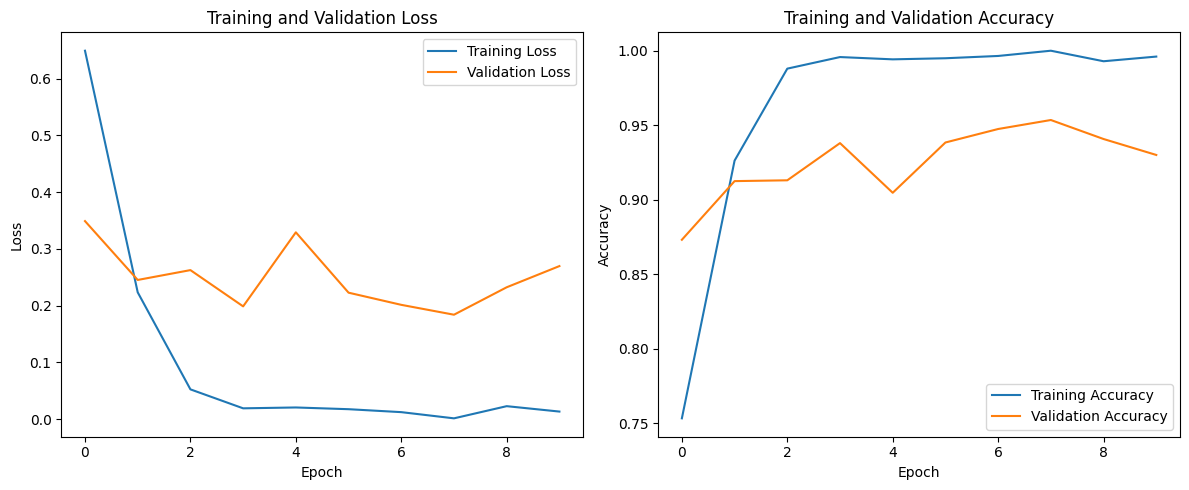

In [ ]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot([acc.item() for acc in train_accs], label='Training Accuracy')
plt.plot([acc.item() for acc in val_accs], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

**Testing & Metrics**

In [ ]:
def test_model(model, test_loader):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs).logits
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    return all_labels, all_preds, all_probs

test_labels, test_preds, test_probs = test_model(trained_model, test_loader)

# Metrics
accuracy_val = accuracy(torch.tensor(test_preds).to(device), torch.tensor(test_labels).to(device))
precision_val = precision(torch.tensor(test_preds).to(device), torch.tensor(test_labels).to(device))
recall_val = recall(torch.tensor(test_preds).to(device), torch.tensor(test_labels).to(device))
f1_val = f1(torch.tensor(test_preds).to(device), torch.tensor(test_labels).to(device))
auroc_val = auroc(torch.tensor(test_probs).to(device), torch.tensor(test_labels).to(device))

print(f"Accuracy: {accuracy_val:.4f}")
print(f"Precision: {precision_val:.4f}")
print(f"Recall: {recall_val:.4f}")
print(f"F1 Score: {f1_val:.4f}")
print(f"AUROC: {auroc_val:.4f}")
print("\nClassification Report:")
print(classification_report(test_labels, test_preds, target_names=class_names))

/tmp/ipython-input-10-927453298.py:29: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:254.)
  auroc_val = auroc(torch.tensor(test_probs).to(device), torch.tensor(test_labels).to(device))


Accuracy: 0.9120
Precision: 0.9125
Recall: 0.9119
F1 Score: 0.9112
AUROC: 0.9900

Classification Report:
               precision    recall  f1-score   support

      baroque       0.89      0.98      0.93      2073
expressionism       0.92      0.98      0.95      2101
impressionism       0.95      0.87      0.91      2093
      realism       0.90      0.85      0.87      2070
  romanticism       0.90      0.88      0.89      2085

     accuracy                           0.91     10422
    macro avg       0.91      0.91      0.91     10422
 weighted avg       0.91      0.91      0.91     10422



**Confusion Matrix**

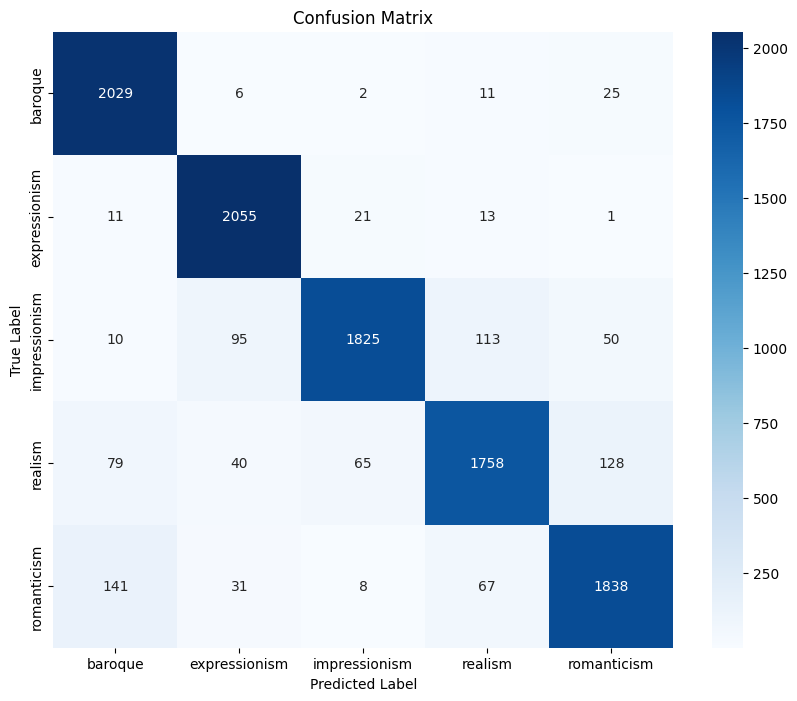

In [ ]:
plt.figure(figsize=(10, 8))
cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

**ROC Curve**

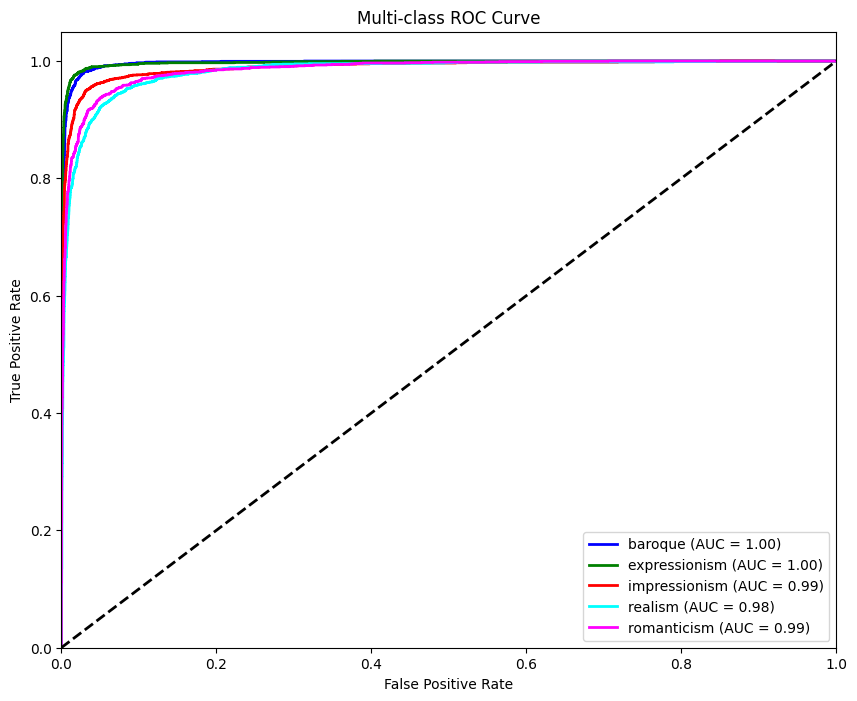

In [ ]:
def plot_roc_curve(y_true, y_probs, classes):
    y_true_bin = label_binarize(y_true, classes=np.arange(len(classes)))
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(len(classes)):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], np.array(y_probs)[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(10, 8))
    colors = ['blue', 'green', 'red', 'cyan', 'magenta']
    for i, color in zip(range(len(classes)), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label='{0} (AUC = {1:0.2f})'.format(classes[i], roc_auc[i]))

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Multi-class ROC Curve')
    plt.legend(loc="lower right")
    plt.show()

plot_roc_curve(test_labels, test_probs, class_names)

**Save Results**

In [ ]:
results = {
    'model': 'ViT (second run)',
    'training_time': training_time,
    'accuracy': accuracy_val.item(),
    'precision': precision_val.item(),
    'recall': recall_val.item(),
    'f1_score': f1_val.item(),
    'auroc': auroc_val.item(),
    'num_epochs': num_epochs,
    'batch_size': batch_size
}

results_df = pd.DataFrame([results])
results_df.to_csv('vit_second_run_results.csv', index=False)
torch.save(trained_model.state_dict(), 'vit_second_run_art_classifier.pth')

**Sample Predictions**

/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


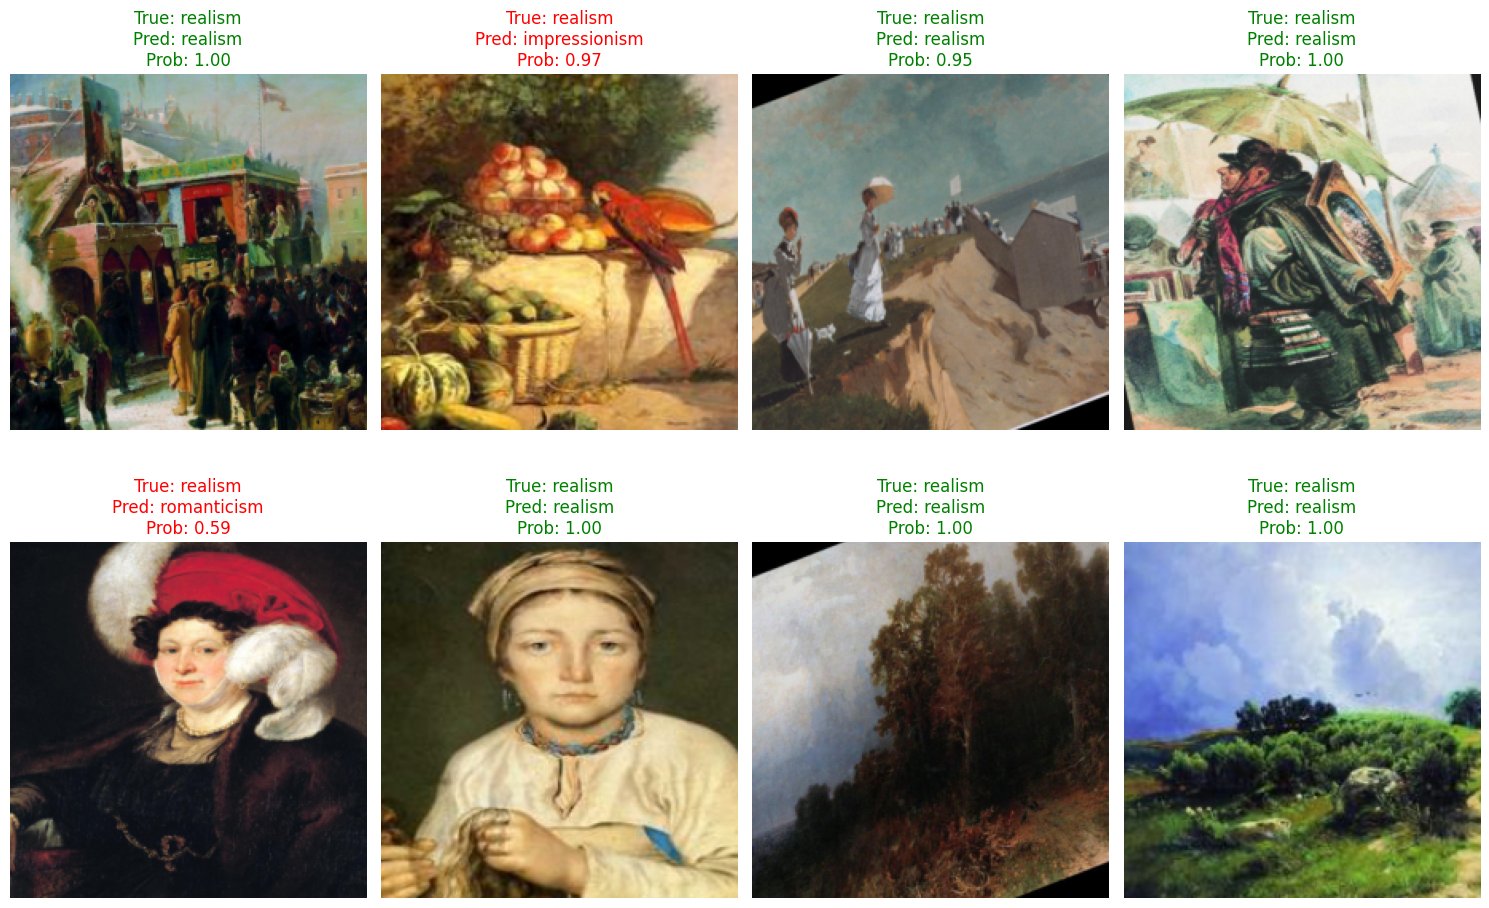

In [ ]:
def plot_sample_predictions(model, data_loader, class_names, num_samples=8):
    model.eval()
    images, labels = next(iter(data_loader))
    images = images.to(device)
    labels = labels.to(device)

    with torch.no_grad():
        outputs = model(images).logits
        _, preds = torch.max(outputs, 1)
        probs = torch.softmax(outputs, dim=1)

    images = images.cpu()
    labels = labels.cpu()
    preds = preds.cpu()
    probs = probs.cpu()

    plt.figure(figsize=(15, 10))
    for i in range(num_samples):
        plt.subplot(2, 4, i+1)
        img = images[i].permute(1, 2, 0).numpy()
        img = img * np.array([0.5, 0.5, 0.5]) + np.array([0.5, 0.5, 0.5])  # Unnormalize
        img = np.clip(img, 0, 1)

        plt.imshow(img)
        true_label = class_names[labels[i]]
        pred_label = class_names[preds[i]]
        prob = probs[i][preds[i]].item()

        title = f'True: {true_label}\nPred: {pred_label}\nProb: {prob:.2f}'
        color = 'green' if pred_label == true_label else 'red'
        plt.title(title, color=color)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

plot_sample_predictions(trained_model, plotting_test_loader, class_names)